# **Fold your name: protein structure prediction with ESMFold**

*Utrecht University Molecular Modelling courses from the [Bonvin lab](https://bonvinlab.org).*

A protein is a chain of amino acids, written as a sequence of one-letter codes. The sequence determines
how the chain folds into a 3D structure, and since AlphaFold2 (Nobel Prize in Chemistry 2024) computers
predict that structure remarkably well. In this notebook you write **your own name** (and, if you like,
your address) as a protein sequence, let **ESMFold** predict its structure, and find out

* **what structure your name folds into** — helices, strands, or nothing at all, and
* **whether you should believe it** — how confident the prediction is.

### ESMFold in brief

**ESMFold** (Z. Lin *et al.*, *Science* **379**, 1123–1130, 2023) combines a **protein language model**
(ESM-2), trained on hundreds of millions of natural protein sequences in the way chat bots are trained on
text, with a **structure module** that turns what the language model "understands" of a sequence into 3D
coordinates. It needs **a single sequence** only. AlphaFold2 and its successors (AlphaFold3, Chai-1,
Boltz, Protenix, OpenFold3) also search a database for **related sequences** (a multiple sequence
alignment, MSA) and learn from how they evolved. Your name has no evolutionary relatives, so a
single-sequence method is the natural choice here.

### How confident is the prediction?

A predictor **always** returns coordinates, even for nonsense. What tells you whether to believe them is
its own confidence estimate:

* **pLDDT** (predicted local distance difference test), for every residue, on a scale of 0–100:

| pLDDT | colour used here | meaning |
|---|---|---|
| > 90 | dark blue | very high: backbone and side chains reliable |
| 70–90 | light blue | confident: backbone reliable |
| 50–70 | yellow | low: treat with caution |
| < 50 | orange | very low: probably disordered, do not interpret |

* **pTM** (predicted TM-score), one number (0–1) for the **whole structure**. The TM-score measures how
  well two structures superimpose over their full length: 1 = identical, above ≈0.5 = the same fold,
  below ≈0.2 = unrelated. The pTM is the predictor's estimate of the TM-score between its model and the
  (unknown) true structure, so it tells you whether the **overall fold**, the way the helices and strands
  are arranged with respect to each other, is likely right. A high pLDDT with a low pTM means: the pieces
  are right locally, but their arrangement is uncertain.

  ESMFold computes the pTM, but the free server sends back only the coordinates (with the pLDDT). This
  notebook therefore shows the pTM only for the **pre-computed** structures; the web servers listed in
  step 2 show it with their results.

### How this notebook gets a structure

The prediction itself is done by **ESMFold on a free server** (the ESM Metagenomic Atlas of Meta AI): your
sequence is sent to it and the predicted structure comes back within seconds. That server is not always
available. If it does not answer, you can

1. predict the structure of your sequence yourself on one of the free web servers listed in step 2 and
   **upload** the result into this notebook, or
2. carry on with a **pre-computed example** (the sentence "MATHEMATICS, DATA AND MOLECULAR MODELLING"),
   so that you can still do every step.

> **Privacy.** Your sequence is **sent to an external server** (in step 2). If you prefer not to send your name or address, use part of it, a fictional address (or the university's), or any other text you like.


> **Solutions version — for instructors / checking only.** Step 1 is filled in with the example text "MATHEMATICS, DATA AND MOLECULAR MODELLING" and the answer blocks are unfolded, so all figures and numbers can be compared with the answers. The student version is `Notebooks/Structure-prediction-ESMFold.ipynb`.

## **Showing and hiding the code**

Cells that only install packages, define helper tools or draw figures **start collapsed**: you see what
they produce, not the code. A collapsed cell runs exactly like an open one. Click the blue bar left of a
cell (or *View → Collapse/Expand*) to open or close it. The cells you need to edit are open.

In [1]:
# --- Install required packages (works locally, on Colab, and on JupyterLite) ---
%pip install -q py3Dmol biopython matplotlib numpy

import difflib, random, unicodedata
from html import escape
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import sys, warnings
if sys.platform == "emscripten":   # JupyterLite: its matplotlib build warns on every text label
    warnings.filterwarnings("ignore", message=r"The \w+ parameter as float was deprecated")
import py3Dmol
from IPython.display import HTML, display
%matplotlib inline


[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: /Users/abonvin/haddock_git/haddock3/.venv-3.14/bin/python3.14 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
# --- Toolbox: reading structures, secondary structure, 3D views (no need to read this) ---

AMINO_ACIDS = "ACDEFGHIKLMNPQRSTVWY"
EXAMPLE_TEXT = "MATHEMATICS, DATA AND MOLECULAR MODELLING"
EXAMPLE_SEQUENCE = "MATHEMATICSDATAANDMLECLARMDELLING"
UBIQUITIN = "MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG"
SS_COLOR = {"H": "#d6336c", "E": "#f0a30a", "-": "#b9b9b9"}         # helix, strand, coil
SS_NAME = {"H": "helix", "E": "strand", "-": "coil"}


def plddt_color(p):
    """AlphaFold colour scheme for a pLDDT value (0-100)."""
    return "#0053d6" if p > 90 else "#65cbf3" if p > 70 else "#ffdb13" if p > 50 else "#ff7d45"


def show_box(lines, ok):
    """A green (ok) or red box with a few lines of text."""
    color, bg = ("#1a7f37", "#e6f4ea") if ok else ("#b42318", "#fdecea")
    body = "<br>".join(escape(line) for line in lines)
    display({"text/html": f'<div style="border-left: 6px solid {color}; background: {bg}; padding: 8px 12px; '
                          f'margin: 4px 0; color: #222;">{body}</div>',
             "text/plain": "\n".join(lines)}, raw=True)


def show_wide(text):
    """Show printed text without wrapping long lines (a horizontal scroll bar instead)."""
    style = ("white-space: pre; overflow-x: auto; margin: 0 0 1em 0; line-height: 1.3; "
             "font-family: var(--jp-code-font-family, monospace); font-size: var(--jp-code-font-size, 13px);")
    display({"text/html": f'<pre style="{style}">{escape(text)}</pre>', "text/plain": text}, raw=True)


def show_html(document, height=480):
    """Show a complete HTML document in an iframe (how 3D viewers run in JupyterLab/JupyterLite/Colab)."""
    display(HTML(f'<div><iframe srcdoc="{escape(document, quote=True)}" width="100%" height="{height}" '
                 'style="border:none" allow="fullscreen"></iframe></div>'))


def show3d(view, legend="", height=480):
    show_html("<!doctype html><html><body style='margin:0; font-family: sans-serif; font-size: 13px'>"
              f"{legend}{view.write_html()}</body></html>", height=height + (30 if legend else 0))


def legend_html(items):
    return ("<div style='padding: 4px 0'>" + " ".join(
        f"<span style='display:inline-block; width:12px; height:12px; background:{c}; "
        f"vertical-align:middle; margin: 0 4px 0 10px'></span>{escape(t)}" for t, c in items) + "</div>")


# ---------- reading a predicted structure ----------
THREE_TO_ONE = {"ALA": "A", "CYS": "C", "ASP": "D", "GLU": "E", "PHE": "F", "GLY": "G", "HIS": "H",
                "ILE": "I", "LYS": "K", "LEU": "L", "MET": "M", "ASN": "N", "PRO": "P", "GLN": "Q",
                "ARG": "R", "SER": "S", "THR": "T", "VAL": "V", "TRP": "W", "TYR": "Y"}


def cif_to_pdb(text):
    """Convert an mmCIF file (e.g. from Chai-1, Boltz, Protenix, OpenFold3, AlphaFold3) to PDB text."""
    from io import StringIO
    from Bio.PDB import MMCIFParser, PDBIO
    structure = MMCIFParser(QUIET=True).get_structure("model", StringIO(text))
    out = StringIO()
    io = PDBIO(); io.set_structure(structure); io.save(out)
    return out.getvalue()


def read_backbone(pdb_text):
    """Backbone N, CA, C, O coordinates, sequence and pLDDT (0-100) of the first chain of the first model."""
    atoms, order, chain = {}, [], None
    for line in pdb_text.splitlines():
        if line.startswith("ENDMDL"):
            break
        if not line.startswith("ATOM"):
            continue
        if chain is None:
            chain = line[21]
        if line[21] != chain or line[16] not in " A":
            continue
        key = (int(line[22:26]), line[26])
        if key not in atoms:
            atoms[key] = {"resname": line[17:20]}
            order.append(key)
        atoms[key][line[12:16].strip()] = ([float(line[30:38]), float(line[38:46]), float(line[46:54])],
                                           float(line[60:66]))
    order = [k for k in order if all(a in atoms[k] for a in ("N", "CA", "C", "O"))]
    xyz = {a: np.array([atoms[k][a][0] for k in order]) for a in ("N", "CA", "C", "O")}
    plddt = np.array([atoms[k]["CA"][1] for k in order])
    if plddt.max() <= 1.0:                      # some servers write pLDDT as 0-1
        plddt = 100 * plddt
    resnames = [atoms[k]["resname"] for k in order]
    sequence = "".join(THREE_TO_ONE.get(r, "X") for r in resnames)
    return {"xyz": xyz, "resnames": resnames, "sequence": sequence, "plddt": plddt,
            "resi": [k[0] for k in order]}


# ---------- secondary structure: a simplified DSSP ----------
def hbond_matrix(xyz, resnames):
    """hb[i, j]: the C=O of residue i accepts a hydrogen bond from the N-H of residue j.
       DSSP electrostatic model: E = 0.084 * 332 * (1/rON + 1/rCH - 1/rOH - 1/rCN) < -0.5 kcal/mol."""
    N, C, O = xyz["N"], xyz["C"], xyz["O"]
    co = C[:-1] - O[:-1]
    H = N.copy()                                          # amide H, placed along the previous C=O
    H[1:] = N[1:] + co / np.linalg.norm(co, axis=1)[:, None]
    dist = lambda a, b: np.linalg.norm(a[:, None, :] - b[None, :, :], axis=-1)
    with np.errstate(divide="ignore"):
        energy = 0.084 * 332 * (1 / dist(O, N) + 1 / dist(C, H) - 1 / dist(O, H) - 1 / dist(C, N))
    hb = energy < -0.5
    idx = np.arange(len(N))
    hb[:, 0] = False                                      # the first residue has no amide H
    hb[:, [r == "PRO" for r in resnames]] = False         # proline has no amide H
    hb[np.abs(idx[:, None] - idx[None, :]) < 2] = False
    return hb


def assign_ss(model):
    """Simplified DSSP: 'H' alpha-helix (two consecutive i -> i+4 H-bonded turns), 'E' strand
       (residue in a parallel or antiparallel bridge), '-' anything else (3-10 helices count as coil)."""
    hb = hbond_matrix(model["xyz"], model["resnames"])
    n = len(hb)
    ss = np.array(["-"] * n)
    turn = [i + 4 < n and hb[i, i + 4] for i in range(n)]
    for i in range(1, n - 3):
        if turn[i - 1] and turn[i]:
            ss[i:i + 4] = "H"
    H = lambda i, j: 0 <= i < n and 0 <= j < n and hb[i, j]
    for i in range(1, n - 1):
        for j in range(1, n - 1):
            if abs(i - j) > 2 and ss[i] != "H" and (
                    (H(i - 1, j) and H(j, i + 1)) or (H(j - 1, i) and H(i, j + 1))            # parallel
                    or (H(i, j) and H(j, i)) or (H(i - 1, j + 1) and H(j - 1, i + 1))):    # antiparallel
                ss[i] = "E"
    return "".join(ss)


def phi_psi(xyz):
    """Backbone dihedral angles phi and psi (degrees) of every residue (NaN at the chain ends)."""
    def dihedral(p0, p1, p2, p3):
        b0, b1, b2 = p0 - p1, p2 - p1, p3 - p2
        b1 = b1 / np.linalg.norm(b1, axis=-1, keepdims=True)
        v = b0 - (b0 * b1).sum(-1, keepdims=True) * b1
        w = b2 - (b2 * b1).sum(-1, keepdims=True) * b1
        return np.degrees(np.arctan2((np.cross(b1, v) * w).sum(-1), (v * w).sum(-1)))
    N, CA, C = xyz["N"], xyz["CA"], xyz["C"]
    phi = np.full(len(N), np.nan); psi = np.full(len(N), np.nan)
    phi[1:] = dihedral(C[:-1], N[1:], CA[1:], C[1:])
    psi[:-1] = dihedral(N[:-1], CA[:-1], C[:-1], N[1:])
    return phi, psi


def with_ss_records(pdb_text, model):
    """Add HELIX/SHEET records for our assignment, so the 3D cartoon shows the same secondary structure."""
    records, ss, resi = [], model["ss"], model["resi"]
    chain = next(l[21] for l in pdb_text.splitlines() if l.startswith("ATOM"))
    i = 0
    while i < len(ss):
        j = i
        while j + 1 < len(ss) and ss[j + 1] == ss[i]:
            j += 1
        a, b = model["resnames"][i], model["resnames"][j]
        if ss[i] == "H":
            records.append(f"HELIX  {len(records) + 1:3d} {len(records) + 1:3d} {a} {chain} {resi[i]:4d}  "
                           f"{b} {chain} {resi[j]:4d}  1{'':30}{j - i + 1:5d}")
        elif ss[i] == "E":
            records.append(f"SHEET  {len(records) + 1:3d} S{len(records) + 1:<2d} 1 {a} {chain}{resi[i]:4d}  "
                           f"{b} {chain}{resi[j]:4d}  0")
        i = j + 1
    # (a bare "END" line makes 3Dmol forget the HELIX/SHEET records, so leave it out)
    body = [l for l in pdb_text.splitlines() if not l.startswith(("HELIX", "SHEET")) and l.strip() != "END"]
    return "\n".join(records + body) + "\n"


def analyse(pdb_text, source):
    """Everything the notebook needs about one predicted structure."""
    model = read_backbone(pdb_text)
    model["source"] = source
    model["ss"] = assign_ss(model)
    model["phi"], model["psi"] = phi_psi(model["xyz"])
    model["pdb"] = with_ss_records(pdb_text, model)
    return model


def summary(model):
    p, ss = model["plddt"], model["ss"]
    return {"length": len(ss), "mean_plddt": p.mean(), "confident": np.mean(p > 70),
            "helix": ss.count("H") / len(ss), "strand": ss.count("E") / len(ss)}


# ---------- 3D views ----------
def view_structure(model, width=800, height=440, labels=True):
    """Cartoon coloured by pLDDT."""
    view = py3Dmol.view(width=width, height=height)
    view.addModel(model["pdb"], "pdb", {"noComputeSecondaryStructure": True})   # use our HELIX/SHEET
    for r, p in zip(model["resi"], model["plddt"]):
        view.setStyle({"resi": r}, {"cartoon": {"color": plddt_color(p)}})
    if labels and len(model["resi"]) <= 60:               # the letter of each residue at its CA
        for r, aa in zip(model["resi"], model["sequence"]):
            view.addLabel(aa, {"fontSize": 11, "fontColor": "black", "backgroundColor": "white",
                               "backgroundOpacity": 0.6, "inFront": True}, {"resi": r, "atom": "CA"})
    view.zoomTo()
    return view


PLDDT_LEGEND = legend_html([("> 90", "#0053d6"), ("70-90", "#65cbf3"), ("50-70", "#ffdb13"),
                            ("< 50", "#ff7d45")])


# ---------- step 1: validation of the sequence ----------
def expected_sequence(text):
    """The text in capitals, accents removed (é -> E), keeping only the 20 one-letter codes."""
    plain = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode().upper()
    return "".join(c for c in plain if c in AMINO_ACIDS)


def validate(text, sequence, name="MY_SEQUENCE", min_length=10, max_length=400):
    """Check a sequence; show a green or red box; return True when it is ready for prediction.
       text: the text it was made from (MY_TEXT), or None for a designed sequence."""
    if not sequence.strip() and (text is None or not text.strip()):
        print(f"Not yet: fill in {name if text is None else 'MY_TEXT and ' + name} in the cell above, "
              "then run this cell again.")
        return False
    problems = []
    if not sequence:
        problems.append(f"{name} is empty: write your text there, keeping only the 20 amino-acid codes.")
    for pos, c in enumerate(sequence, start=1):
        if c in AMINO_ACIDS:
            continue
        if c.upper() in AMINO_ACIDS:
            problems.append(f"position {pos}: '{c}' is lower case: write amino acids in capitals ('{c.upper()}').")
        elif c == " ":
            problems.append(f"position {pos}: a space: remove it.")
        elif c.isalpha() and c.upper() in "BJOUXZ":
            problems.append(f"position {pos}: '{c}' is not one of the 20 amino-acid codes: remove it.")
        else:
            problems.append(f"position {pos}: '{c}' is not an amino acid: remove it.")
    if not problems and text is not None:
        want = expected_sequence(text)
        if sequence != want:
            for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, want, sequence, autojunk=False).get_opcodes():
                if tag in ("delete", "replace"):
                    problems.append(f"'{want[i1:i2]}' is missing after position {j1} of MY_SEQUENCE: "
                                    "it is an amino acid in MY_TEXT, so keep it.")
                if tag in ("insert", "replace"):
                    problems.append(f"'{sequence[j1:j2]}' at position {j1 + 1} of MY_SEQUENCE does not match "
                                    "MY_TEXT there: keep the letters of MY_TEXT, in the same order.")
    if not problems and len(sequence) < min_length:
        problems.append(f"only {len(sequence)} amino acids: too short to fold. "
                        + ("Add your address or more text " if text is not None else "Make it longer ")
                        + f"(at least {min_length}).")
    if not problems and len(sequence) > max_length:
        problems.append(f"{len(sequence)} amino acids: at most {max_length} here. Make it shorter.")
    if problems:
        show_box([f"❌ Not ready yet. Correct {name} and run this cell again:"] + problems[:10]
                 + (["..."] if len(problems) > 10 else []), ok=False)
        return False
    show_box([f"✅ Ready for prediction: {len(sequence)} amino acids.", sequence], ok=True)
    return True


def not_yet():
    print("Not yet: your sequence has not passed the validation in step 1.")


def report_design(model):
    """Exercise (step 7): is the predicted structure of a designed sequence a beta-sheet?"""
    seq, ss = model["sequence"], model["ss"]
    n_strands = len("".join(c if c == "E" else " " for c in ss).split())
    s = summary(model)
    show_wide("\n".join([f"sequence   {seq}", f"structure  {ss}      H = helix, E = strand, - = coil"]))
    numbers = (f"{n_strands} strand(s), {100 * s['strand']:.0f} % of the residues in strands, "
               f"{100 * s['helix']:.0f} % in helices; mean pLDDT {s['mean_plddt']:.0f}"
               + (f", pTM {model['ptm']:.2f}" if "ptm" in model else ""))
    if n_strands >= 2 and s["strand"] >= 0.4 and s["mean_plddt"] >= 70:
        show_box(["✅ A beta-sheet, predicted with confidence: " + numbers], ok=True)
    else:
        reasons = []
        if n_strands < 2:
            reasons.append("a sheet needs at least two strands that pair")
        if s["strand"] < 0.4:
            reasons.append("less than 40 % of the residues are in strands")
        if s["mean_plddt"] < 70:
            reasons.append("the prediction is not confident (mean pLDDT below 70)")
        show_box(["❌ Not a beta-sheet yet: " + numbers] + reasons + ["Change MY_DESIGN and try again."], ok=False)

In [3]:
# --- The pre-computed example structures (used when the server is not available) ---
import json, urllib.request

EXAMPLES = {"example": EXAMPLE_SEQUENCE, "example_shuffled": "TDSIELTNMACCMDNDLTAMMLAAELARAHGEI",
            "ubiquitin": UBIQUITIN, "ubiquitin_shuffled": "SLISTYPSLTVPVRREKIVKLKGQIGGQQTLIIDQEETNTLLGRADQDTPLGGKFMLHDANRVFKIKQIDEEKTLE",
            "design_example": "TVTVTVTVTVNGKTVTVTVTVTV"}
URL = "https://raw.githubusercontent.com/haddocking/molmod-education/main/Notebooks/ESMFold-data/"


FILES = ["confidence.json"] + [f"{name}.pdb" for name in EXAMPLES]


def find_data_dir():
    for d in (Path("ESMFold-data"), Path("Notebooks/ESMFold-data"), Path("../Notebooks/ESMFold-data")):
        if all((d / f).exists() for f in FILES):
            return d
    d = Path("ESMFold-data")                 # e.g. on Colab: download them
    d.mkdir(exist_ok=True)
    for f in FILES:
        urllib.request.urlretrieve(URL + f, d / f)
    return d


DATA_DIR = find_data_dir()
PRECOMPUTED = {seq: (DATA_DIR / f"{name}.pdb").read_text() for name, seq in EXAMPLES.items()}
PTM = {c["sequence"]: c["ptm"] for c in json.loads((DATA_DIR / "confidence.json").read_text()).values()}


def with_confidence(model):
    """Add the pTM of a pre-computed structure (the free server returns only the structure)."""
    if "pre-computed" in model["source"] and model["sequence"] in PTM:
        model["ptm"] = PTM[model["sequence"]]
    return model


print("example structures in", DATA_DIR)

example structures in ../Notebooks/ESMFold-data


---
## **1. Step 1: your name as a protein sequence**

Proteins are built from **20 amino acids**, each written with a one-letter code:

| Code | Three-letter | Amino acid | Property | | Code | Three-letter | Amino acid | Property |
|---|---|---|---|---|---|---|---|---|
| **A** | Ala | Alanine | hydrophobic | | **M** | Met | Methionine | hydrophobic |
| **C** | Cys | Cysteine | polar (can form S–S bridges) | | **N** | Asn | Asparagine | polar |
| **D** | Asp | Aspartate | negatively charged | | **P** | Pro | Proline | special: rigid, breaks helices |
| **E** | Glu | Glutamate | negatively charged | | **Q** | Gln | Glutamine | polar |
| **F** | Phe | Phenylalanine | hydrophobic, aromatic | | **R** | Arg | Arginine | positively charged |
| **G** | Gly | Glycine | special: very flexible | | **S** | Ser | Serine | polar |
| **H** | His | Histidine | polar / positively charged | | **T** | Thr | Threonine | polar |
| **I** | Ile | Isoleucine | hydrophobic | | **V** | Val | Valine | hydrophobic |
| **K** | Lys | Lysine | positively charged | | **W** | Trp | Tryptophan | hydrophobic, aromatic |
| **L** | Leu | Leucine | hydrophobic | | **Y** | Tyr | Tyrosine | polar, aromatic |

Six letters of the alphabet are **not** among them: **B, J, O, U, X** and **Z**. (Some are used for
special cases — B and Z for "D or N" and "E or Q", X for "any", U and O for the rare selenocysteine and
pyrrolysine — but a structure predictor does not accept them.) Spaces, digits and punctuation are not
amino acids either.

**Your task.** In the cell below:

1. write your **name** in `MY_TEXT`, exactly as you would write it. If you like, add your **address**:
   a longer sequence gives the protein more to fold;
2. write the **same text in `MY_SEQUENCE`, keeping only the 20 amino-acid codes**: remove spaces, digits,
   punctuation and the letters B, J, O, U, X and Z, and write everything in **capitals**. A letter with an
   accent counts as the plain letter (é → E, ü → U).

Then run the **validation cell**. It gives you the **green light** for the prediction, or tells you what
to correct.

In [4]:
# ---------- Step 1: your text and your protein sequence ----------
MY_TEXT     = "MATHEMATICS, DATA AND MOLECULAR MODELLING"     # your name (and address), as you would write it
MY_SEQUENCE = "MATHEMATICSDATAANDMLECLARMDELLING"     # the same text, keeping ONLY the 20 one-letter codes, in capitals, no spaces

In [5]:
# ---------- Validation: green light for the prediction? ----------
SEQUENCE_OK = validate(MY_TEXT, MY_SEQUENCE)
if SEQUENCE_OK:
    counts = {aa: MY_SEQUENCE.count(aa) for aa in AMINO_ACIDS if aa in MY_SEQUENCE}
    print("composition:", "  ".join(f"{aa} {n}" for aa, n in sorted(counts.items(), key=lambda x: -x[1])))
    print("amino acids your text does not contain:", " ".join(aa for aa in AMINO_ACIDS if aa not in counts))

✅ Ready for prediction: 33 amino acids.
MATHEMATICSDATAANDMLECLARMDELLING

composition: A 6  L 4  M 4  D 3  E 3  T 3  C 2  I 2  N 2  G 1  H 1  R 1  S 1
amino acids your text does not contain: F K P Q V W Y


**Questions**

**(a)** Which characters of your text are not amino acids? How long is your protein?

**(b)** Which amino acids does your protein contain most of? Using the table above: is it mostly
hydrophobic, polar or charged?

<details open>
<summary><b>Step 1 — answers (example)</b></summary>

For the example text "MATHEMATICS, DATA AND MOLECULAR MODELLING":

**(a)** The four spaces, the comma, and the letters **O** (×2) and **U** (×1) are removed, leaving
`MATHEMATICSDATAANDMLECLARMDELLING`: **33 amino acids**.

**(b)** A 6, M 4, L 4, then T, E and D 3 each, are the most frequent: a mix of hydrophobic residues
(A, M, L, I), negatively charged ones (D, E) and polar ones (T, C, N, S). There are no aromatic residues
(F, W, Y) and only one positive charge (R).
</details>

---
## **2. Step 2: predict the structure**

The next cell sends your sequence to the **ESMFold server of the ESM Metagenomic Atlas** and receives the
predicted structure as a PDB file (saved as `my_structure.pdb`). It usually takes a few seconds.

**If the server does not answer** (it is a free service and sometimes down), you have two options:

1. **Predict it elsewhere and upload the result.** Paste your sequence into one of the free servers
   below, download the predicted structure (`.pdb` or `.cif`), upload it into this notebook's folder
   (the file browser on the left: *Upload*), write its name in `MY_STRUCTURE_FILE` below and run the
   cell again.
2. **Do nothing**: the notebook then continues with the pre-computed example, "MATHEMATICS, DATA AND
   MOLECULAR MODELLING", so you can still do every step (and redo them later with your own sequence).

**Free servers for structure prediction**

| Server | Method | Access | Reference |
|---|---|---|---|
| [AlphaFold Server](https://alphafoldserver.com) | AlphaFold3 | free Google account, a limited number of jobs per day | J. Abramson *et al.*, *Nature* **630**, 493–500 (2024) |
| [ColabFold](https://colab.research.google.com/github/sokrypton/ColabFold/blob/main/AlphaFold2.ipynb) | AlphaFold2, run in a Google Colab notebook | free Google account; choose a GPU runtime | M. Mirdita *et al.*, *Nat. Methods* **19**, 679–682 (2022); J. Jumper *et al.*, *Nature* **596**, 583–589 (2021) |
| [Protenix server](https://protenix-server.com) | Protenix | free account | ByteDance AML AI4Science team, *bioRxiv* (2025), doi:10.1101/2025.01.08.631967 |
| [Tamarind Bio](https://app.tamarind.bio/boltz) | Boltz-2 | free account, a few free jobs | S. Passaro *et al.*, *bioRxiv* (2025), doi:10.1101/2025.06.14.659707 |
| [Neurosnap](https://neurosnap.ai/service/OpenFold3%20%28AlphaFold3%29) | OpenFold3 (also Boltz-2 and others) | free account | [github.com/aqlaboratory/openfold-3](https://github.com/aqlaboratory/openfold-3) |
| [ESM Metagenomic Atlas](https://esmatlas.com/resources?action=fold) | ESMFold (the server this notebook uses) | no account | Z. Lin *et al.*, *Science* **379**, 1123–1130 (2023) |

All of them store the **pLDDT** in the structure file, which this notebook reads. Except ESMFold, they are
AlphaFold-type methods that normally use a multiple sequence alignment (MSA). For a name, use a single
protein chain and, if offered, switch the MSA off (*single sequence* mode): your name has no relatives
anyway. Their results will differ from ESMFold's, which is interesting to compare.

In [6]:
MY_STRUCTURE_FILE = ""     # only if the server is down: e.g. "my_prediction.cif" (uploaded file)

In [7]:
# --- Predict the structure: server -> uploaded file -> pre-computed example ---
ESMFOLD_URL = "https://api.esmatlas.com/foldSequence/v1/pdb/"


def post_text(url, text, limit=90):
    """POST plain text and return the answer; give up after `limit` seconds (the server can hang).
       In the browser via XMLHttpRequest, elsewhere via urllib (in a thread, to enforce the limit)."""
    try:
        from js import XMLHttpRequest              # JupyterLite (Pyodide)
    except ImportError:
        import threading, urllib.request
        request = urllib.request.Request(url, data=text.encode(), headers={"Content-Type": "text/plain"})
        result = {}

        def fetch():
            try:
                with urllib.request.urlopen(request, timeout=limit) as answer:
                    result["text"] = answer.read().decode()
            except Exception as error:
                result["error"] = error

        thread = threading.Thread(target=fetch, daemon=True)
        thread.start()
        thread.join(limit)
        if thread.is_alive():
            raise TimeoutError(f"no answer within {limit} s")
        if "error" in result:
            raise result["error"]
        return result["text"]
    xhr = XMLHttpRequest.new()
    xhr.open("POST", url, False)                   # synchronous request
    xhr.timeout = 1000 * limit                     # give up after `limit` seconds
    xhr.setRequestHeader("Content-Type", "text/plain")
    xhr.send(text)
    if xhr.status != 200:
        raise IOError(f"the server answered with status {xhr.status}")
    return xhr.responseText


def predict(sequence, structure_file=""):
    """Return (PDB text, where it came from) for `sequence`."""
    if sequence in PRECOMPUTED:                     # the examples: already predicted with ESMFold
        return PRECOMPUTED[sequence], "ESMFold, pre-computed"
    try:
        pdb = post_text(ESMFOLD_URL, sequence)
        if "ATOM" in pdb:
            return pdb, "ESMFold (ESM Atlas server)"
        raise IOError("the answer is not a structure")
    except Exception as error:
        print(f"The ESMFold server is not available ({error}).")
    if structure_file:
        text = Path(structure_file).read_text()
        pdb = text if "ATOM  " in text[:100000] and not text.lstrip().startswith("data_") else cif_to_pdb(text)
        found = read_backbone(pdb)["sequence"]
        if found != sequence:
            print(f"Warning: the sequence in {structure_file} ({found}) differs from MY_SEQUENCE.")
        return pdb, f"uploaded file {structure_file}"
    return None, None


if not SEQUENCE_OK:
    not_yet()
else:
    pdb, source = predict(MY_SEQUENCE, MY_STRUCTURE_FILE)
    if pdb is None:
        print("No structure for your sequence: upload one (see above), or continue with the example.\n"
              "Continuing with the pre-computed example: " + EXAMPLE_SEQUENCE)
        pdb, source = PRECOMPUTED[EXAMPLE_SEQUENCE], "ESMFold, pre-computed example (not your sequence)"
    MODEL = with_confidence(analyse(pdb, source))
    Path("my_structure.pdb").write_text(MODEL["pdb"])
    show_box([f"Structure of {MODEL['sequence']} ({len(MODEL['sequence'])} amino acids)",
              f"source: {source}", "saved as my_structure.pdb"], ok=True)

Structure of MATHEMATICSDATAANDMLECLARMDELLING (33 amino acids)
source: ESMFold, pre-computed
saved as my_structure.pdb

---
## **3. Step 3: your structure in 3D**

The predicted structure as a **cartoon**, coloured by **confidence (pLDDT)**: helices are drawn as
spirals, strands as arrows, and the rest as a thin tube. Each residue carries its letter (for sequences
up to 60 amino acids). Rotate with the mouse, zoom with the scroll wheel.

In [8]:
if "MODEL" not in globals():
    not_yet()
else:
    print(f"{MODEL['sequence']}   ({MODEL['source']})")
    show3d(view_structure(MODEL), legend="<b>pLDDT</b>" + PLDDT_LEGEND)

MATHEMATICSDATAANDMLECLARMDELLING   (ESMFold, pre-computed)


---
## **4. Step 4: how confident is the prediction?**

**pLDDT** for every residue, with the letters of your text along the axis; the coloured bands are the
four confidence levels of the introduction. Below the plot: the mean pLDDT and the **pTM**, the confidence
in the overall fold (see the introduction). The pTM is only available for the pre-computed structures.

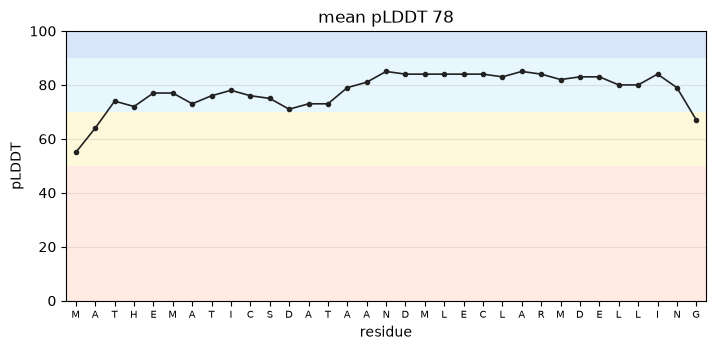

mean pLDDT 77.8;  91 % of the residues above 70
pTM 0.48  (confidence in the overall fold, 0-1; above 0.5: probably the right fold)


In [9]:
def plot_plddt(ax, model, title=None):
    p, n = model["plddt"], len(model["plddt"])
    for lo, hi, col in ((90, 100, "#0053d6"), (70, 90, "#65cbf3"), (50, 70, "#ffdb13"), (0, 50, "#ff7d45")):
        ax.axhspan(lo, hi, color=col, alpha=0.15, lw=0)
    ax.plot(np.arange(1, n + 1), p, "-o", color="#222222", ms=3, lw=1.2)
    ax.set_xlim(0.5, n + 0.5); ax.set_ylim(0, 100)
    if n <= 80:
        ax.set_xticks(np.arange(1, n + 1)); ax.set_xticklabels(list(model["sequence"]), fontsize=7)
    ax.set_xlabel("residue"); ax.set_ylabel("pLDDT")
    ax.set_title(title or f"mean pLDDT {p.mean():.0f}")
    ax.grid(axis="y", alpha=0.3)


if "MODEL" not in globals():
    not_yet()
else:
    s = summary(MODEL)
    fig, ax = plt.subplots(figsize=(max(7, 0.22 * s["length"]), 3.6))
    plot_plddt(ax, MODEL)
    plt.tight_layout(); plt.show()
    print(f"mean pLDDT {s['mean_plddt']:.1f};  {100 * s['confident']:.0f} % of the residues above 70")
    if "ptm" in MODEL:
        print(f"pTM {MODEL['ptm']:.2f}  (confidence in the overall fold, 0-1; above 0.5: probably the right fold)")
    else:
        print(f"pTM not available: the server returns only the coordinates. "
              f"For comparison, the pre-computed example has pTM {PTM[EXAMPLE_SEQUENCE]:.2f}.")

**Question**

**(a)** Which residues are predicted most confidently, and which least?

**(b)** Is the overall fold confident (pTM)? If your structure came from the server, no pTM is available:
answer for the pre-computed example, whose pTM is printed above. What do the mean pLDDT and the pTM tell
you together?

<details open>
<summary><b>Step 4 — answers (example)</b></summary>

For the example (pre-computed):

**(a)** The chain ends are least confident (pLDDT 55 and 64 for the first two residues, 67 for the last);
the second helix (`ANDMLECLARMDELLIN`) is the most confident part (pLDDT ≈ 80–85).

**(b)** The pTM is only 0.48, just below the ≈0.5 of "probably the right fold", although the mean pLDDT is
78: each helix is well predicted locally, but how the two helices are arranged with respect to each other
is uncertain.
</details>

---
## **5. Step 5: secondary structure**

Which parts of the chain form an **α-helix** (H) or a **β-strand** (E)? Both are held together by
**hydrogen bonds between backbone C=O and N–H groups**: in a helix between residue $i$ and residue
$i+4$, in a sheet between residues of neighbouring strands. The standard program to find them, DSSP
(Kabsch & Sander, 1983), computes the energy of every possible C=O···H–N pair and looks for these
patterns. The toolbox uses a simplified version of DSSP (only α-helices and strands; the short
3₁₀-helices count as coil).

Below, the assignment is printed under your sequence, and the **Ramachandran plot** shows the two
backbone angles φ and ψ of every residue: helices and strands each occupy their own region.

position            1         2         3   
sequence   MATHEMATICSDATAANDMLECLARMDELLING
structure  -HHHHHHHHH-----HHHHHHHHHHHHHHHHH-      H = helix, E = strand, - = coil
pLDDT      557777777777777777777777777777775      9 = >90, 7 = 70-90, 5 = 50-70, 0 = <50

helix 79 %   strand 0 %   coil 21 %


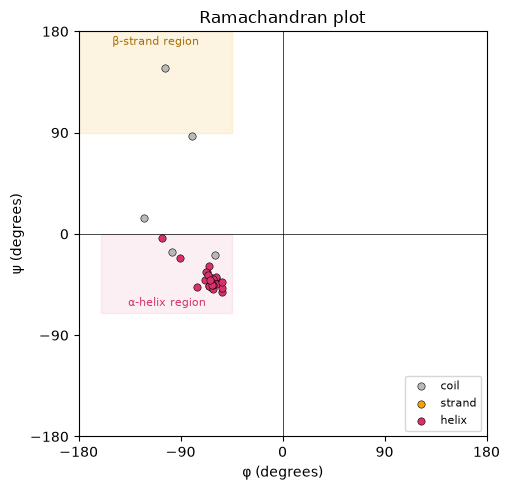

In [10]:
if "MODEL" not in globals():
    not_yet()
else:
    seq, ss, p = MODEL["sequence"], MODEL["ss"], MODEL["plddt"]
    ruler = "".join(str(i // 10 % 10) if i % 10 == 0 else " " for i in range(1, len(seq) + 1))
    conf = "".join("9" if x > 90 else "7" if x > 70 else "5" if x > 50 else "0" for x in p)
    show_wide("\n".join([f"position   {ruler}",
                         f"sequence   {seq}",
                         f"structure  {ss}      H = helix, E = strand, - = coil",
                         f"pLDDT      {conf}      9 = >90, 7 = 70-90, 5 = 50-70, 0 = <50"]))
    s = summary(MODEL)
    print(f"helix {100 * s['helix']:.0f} %   strand {100 * s['strand']:.0f} %   "
          f"coil {100 * (1 - s['helix'] - s['strand']):.0f} %")

    fig, ax = plt.subplots(figsize=(5.2, 5))
    ax.add_patch(plt.Rectangle((-160, -70), 115, 70, color=SS_COLOR["H"], alpha=0.08))
    ax.text(-102, -64, "α-helix region", ha="center", fontsize=8, color=SS_COLOR["H"])
    ax.add_patch(plt.Rectangle((-180, 90), 135, 90, color=SS_COLOR["E"], alpha=0.12))
    ax.text(-112, 168, "β-strand region", ha="center", fontsize=8, color="#a86f00")
    for code in "-EH":
        sel = np.array([c == code for c in ss])
        ax.scatter(MODEL["phi"][sel], MODEL["psi"][sel], s=28, color=SS_COLOR[code], label=SS_NAME[code],
                   edgecolor="k", lw=0.4)
    ax.set_xlim(-180, 180); ax.set_ylim(-180, 180)
    ax.set_xticks(range(-180, 181, 90)); ax.set_yticks(range(-180, 181, 90))
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
    ax.set_xlabel("φ (degrees)"); ax.set_ylabel("ψ (degrees)"); ax.set_title("Ramachandran plot")
    ax.legend(loc="lower right", fontsize=8)
    plt.tight_layout(); plt.show()

---
## **6. Step 6: does your name fold? Compare**

To judge your structure, compare it with a real protein, and both with a **shuffled** version of their
sequence (the same amino acids in a random order), all predicted in the same way:

* **your sequence** and **your sequence shuffled**;
* **ubiquitin**, a small, real protein of 76 amino acids (PDB 1UBQ), whose sequence was shaped by
  evolution, and **ubiquitin shuffled**.

The shuffled sequences answer one question: **does the order of the amino acids matter**, or only which
amino acids there are?

When the server is down, your shuffled sequence can only be shown for the example; ubiquitin and
shuffled ubiquitin are pre-computed.

length mean pLDDT  pLDDT>70  helix  strand   pTM   sequence / structure
your sequence              33       77.8       91%    79%      0%  0.48   MATHEMATICSDATAANDMLECLARMDELLING
                                                                          -HHHHHHHHH-----HHHHHHHHHHHHHHHHH-
your sequence shuffled     33       81.2       97%    85%      0%  0.41   TDSIELTNMACCMDNDLTAMMLAAELARAHGEI
                                                                          -HHHHHHHHHHHHHHHHHHHHHHHHHHHH----
ubiquitin                  76       90.5       96%    16%     34%  0.83   MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG
                                                                          -EEEEEE----EEEEE-----EHHHHHHHHHHHH------EEEEE--EE-----E----------EEEEEE-----
ubiquitin shuffled         76       39.2        0%    12%     11%  0.15   SLISTYPSLTVPVRREKIVKLKGQIGGQQTLIIDQEETNTLLGRADQDTPLGGKFMLHDANRVFKIKQIDEEKTLE
                                                                          ----------------------------------HHHHHHHHH------------EEEE--EEEE-----------

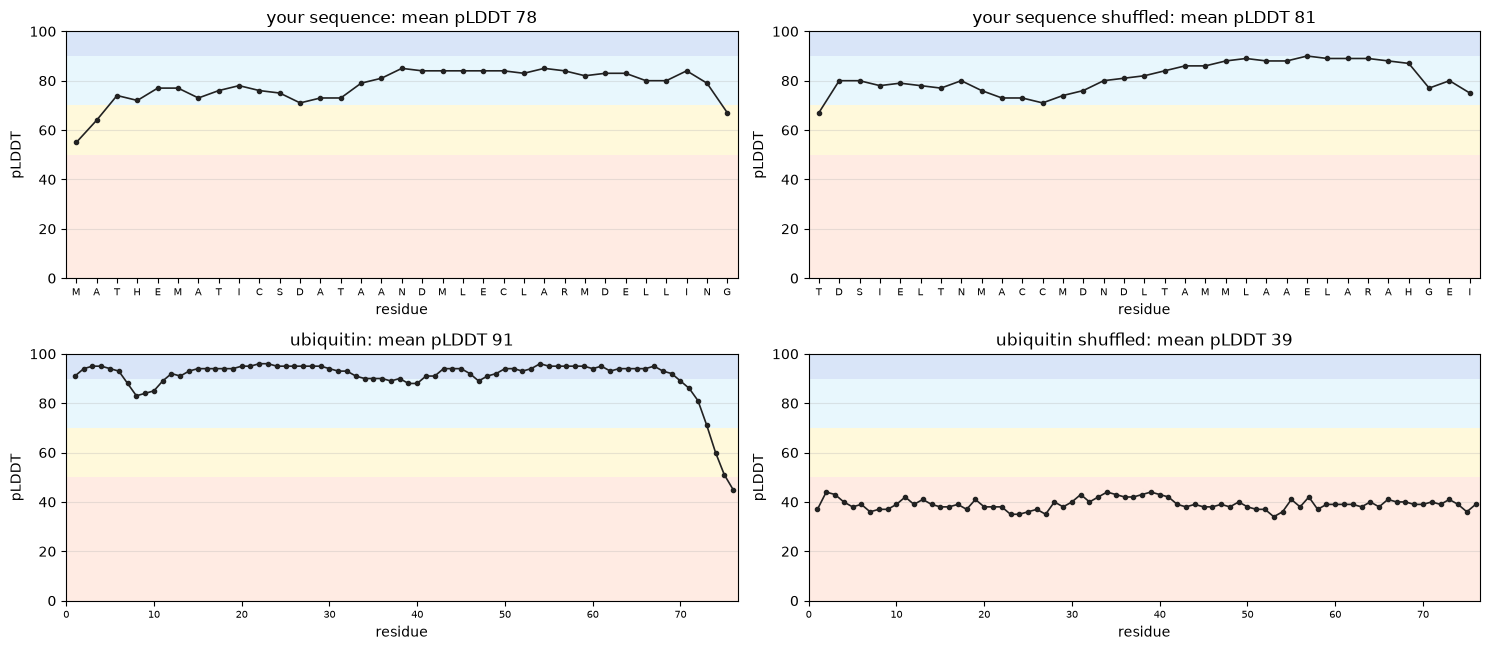

In [11]:
if "MODEL" not in globals():
    not_yet()
else:
    def shuffle(sequence):
        letters = list(sequence); random.Random(1).shuffle(letters)
        return "".join(letters)
    shuffled = shuffle(MODEL["sequence"])
    pdb, source = predict(shuffled)
    if pdb is None:
        print("(the shuffled control needs the server: showing the shuffled example instead)")
        pdb, source = PRECOMPUTED[EXAMPLES["example_shuffled"]], "ESMFold, pre-computed (shuffled example)"
    MODELS = {"your sequence": MODEL,
              "your sequence shuffled": with_confidence(analyse(pdb, source)),
              "ubiquitin": with_confidence(analyse(PRECOMPUTED[UBIQUITIN], "ESMFold, pre-computed")),
              "ubiquitin shuffled": with_confidence(analyse(PRECOMPUTED[shuffle(UBIQUITIN)],
                                                            "ESMFold, pre-computed"))}
    rows = [f"{'':22} {'length':>6} {'mean pLDDT':>10} {'pLDDT>70':>9} {'helix':>6} {'strand':>7}  {'pTM':>4}"
            "   sequence / structure"]
    for name, m in MODELS.items():
        s = summary(m)
        rows.append(f"{name:22} {s['length']:>6} {s['mean_plddt']:>10.1f} {100 * s['confident']:>8.0f}% "
                    f"{100 * s['helix']:>5.0f}% {100 * s['strand']:>6.0f}%  "
                    + (f"{m['ptm']:>4.2f}" if "ptm" in m else f"{'-':>4}") + f"   {m['sequence']}")
        rows.append(f"{'':22} {'':>6} {'':>10} {'':>9} {'':>6} {'':>7}  {'':>4}   {m['ss']}")
    show_wide("\n".join(rows))

    fig, axes = plt.subplots(2, 2, figsize=(15, 6.6))
    for ax, (name, m) in zip(axes.flat, MODELS.items()):
        plot_plddt(ax, m, title=f"{name}: mean pLDDT {m['plddt'].mean():.0f}")
        if len(m["sequence"]) > 40:
            ax.set_xticks(range(0, len(m["sequence"]) + 1, 10)); ax.set_xticklabels(range(0, len(m["sequence"]) + 1, 10))
    plt.tight_layout(); plt.show()

    view = py3Dmol.view(width=800, height=640, viewergrid=(2, 2))
    for k, m in enumerate(MODELS.values()):
        cell = (k // 2, k % 2)
        view.addModel(m["pdb"], "pdb", {"noComputeSecondaryStructure": True}, viewer=cell)
        for r, p in zip(m["resi"], m["plddt"]):
            view.setStyle({"resi": r}, {"cartoon": {"color": plddt_color(p)}}, viewer=cell)
        view.zoomTo(viewer=cell)
    names = list(MODELS)
    show3d(view, legend="<b>pLDDT</b>" + PLDDT_LEGEND + "<div style='padding: 2px 10px'>"
           f"top: {names[0]} | {names[1]};&nbsp;&nbsp; bottom: {names[2]} | {names[3]}</div>", height=640)

**Questions**

**(a)** What structure does your name (or text) fold into: a helix, several helices, strands, or no
regular structure? Which letters are in the helices or strands?

**(b)** How confident is the prediction? Which parts are least confident: the ends, the loops, or
everything?

**(c)** Go back to step 1, **add your address** (or more text) to `MY_TEXT` and `MY_SEQUENCE`, and run
the notebook again (*Run → Run All Cells*). Does the longer protein get more structure, or more
confidence?

**(d)** **Does the order matter?** Compare each sequence with its shuffled version (the same amino acids
in a different order): do they get the same secondary structure and the same confidence? Answer for
your name and for ubiquitin. Why does shuffling change so much more for one of the two?

**(e)** Compare with **ubiquitin**. Why is ESMFold more confident about ubiquitin than about your name?
Think of what the language model was trained on.

**(f)** A structure predictor always returns coordinates. What would you check before believing a
predicted structure?

<details open>
<summary><b>Step 6 — answers (example)</b></summary>

For the example (pre-computed with ESMFold, as when the server is down):

**(a)** Two **α-helices**: residues 2–10 (`ATHEMATIC`) and 16–32 (`ANDMLECLARMDELLIN`), joined by a short
loop at `SDATA`. A helix-loop-helix: the sequence is rich in helix formers (A ×6, M ×4, L ×4, E ×3) and
has few strand formers (T ×3, I ×2, C ×2; no V, F, W or Y). In the Ramachandran plot all helix residues sit
in the α-helix region (φ ≈ −60°, ψ ≈ −45°).

**(b)** Mean pLDDT 78, and 91 % of the residues above 70: *confident*, which is surprisingly high for a
sentence. The least confident residues are the first two (55, 64) and the last one (67): **chain ends**
are always less certain. The loop `SDATA` stays around 71–79.

**(c)** Depends on your text. Usually a longer sequence gives more, or longer, helices, but rarely a
higher confidence: the extra letters do not make the text more "protein-like".

**(d)** For the **name, hardly**: the shuffled example (`TDSIELTNMACCMDNDLTAMMLAAELARAHGEI`) is **one
long helix** (85 % helix) with an even slightly higher mean pLDDT (81 against 78). Its secondary
structure is set by the **composition** (many helix formers); the order only decides where the helix is
broken. A helix is the easiest structure to predict: it only needs local i → i+4 contacts.

For **ubiquitin, completely**: shuffled, its mean pLDDT drops from 90.5 to **39**, no residue is above 70,
and only a short helix and two short strands remain in a mostly disordered chain. The β-sheet of
ubiquitin needs the right residues at the right places along the chain, so that strands far apart in the
sequence can pair. **For a real protein the order encodes the fold**; the name had no fold to lose.

**(e)** Ubiquitin: mean pLDDT 90.5, with a β-sheet and a helix (the fold of the crystal structure 1UBQ),
and a disordered C-terminal tail (`LRGG`, pLDDT 45–60), which is indeed flexible in reality. The language
model has seen ubiquitin and thousands of its relatives during training: it "knows" this protein.
Your name is not a protein, and a high pLDDT for an isolated helix does not mean that this peptide would
be helical in water — single helices are rarely stable on their own.

**(f)** The pLDDT of every residue (not only the mean), the pTM for the whole fold, and whether **different
predictors** (or different runs) give the same structure. And, if possible, compare with experimental
data.
</details>

---
## **7. Exercise: design a β-sheet**

Names and sentences mostly give helices. Now do it the other way round: **design a short sequence
(10–40 amino acids) that ESMFold predicts as a β-sheet**, with at least two strands that pair, and with
confidence (mean pLDDT above 70). Write it in `MY_DESIGN`, then run the three cells below it: the
**validation** (green light), the **prediction** with ESMFold and its 3D model (coloured by pLDDT), and
the **check** whether it is a β-sheet. Try as often as you like.

**Hint.** Favour the **β-branched amino acids**: **valine (V), isoleucine (I) and threonine (T)**.
"β-branched" means that their side chain branches at the **β-carbon**, the first carbon of the side
chain (bonded to Cα): it carries two heavy atoms instead of one (V: two CH₃; I: CH₃ and CH₂–CH₃;
T: CH₃ and OH). That bulk right next to the backbone fits badly in the tightly wound α-helix, but well
in an extended β-strand, where neighbouring side chains point to opposite sides of the strand.

<details>
<summary><b>A second hint</b></summary>

A sheet needs **at least two strands** lying side by side. To make one chain fold back onto itself, put a
**tight turn** between two strands, e.g. the two residues **N-G** (or D-G): glycine is the most flexible
amino acid. Two strands joined by such a turn form a **β-hairpin**.
</details>

In [12]:
# ---------- Exercise: your beta-sheet design ----------
MY_DESIGN = "TVTVTVTVTVNGKTVTVTVTVTV"     # 10-40 amino acids, only the 20 one-letter codes, in capitals

In [13]:
# ---------- Validation of your design ----------
DESIGN_OK = validate(None, MY_DESIGN, name="MY_DESIGN", max_length=40)

✅ Ready for prediction: 23 amino acids.
TVTVTVTVTVNGKTVTVTVTVTV

In [14]:
# ---------- Predict the structure of your design with ESMFold, and show it in 3D ----------
MY_DESIGN_FILE = ""     # only if the server is down: your design predicted elsewhere (.pdb or .cif)

DESIGN = None
if not DESIGN_OK:
    print("Not yet: your design has not passed the validation above.")
else:
    pdb, source = predict(MY_DESIGN, MY_DESIGN_FILE)        # ESMFold server (as in step 2)
    if pdb is None:
        print("No structure for your design: the server is down. Predict it on one of the web servers of "
              "step 2, upload it and write its name in MY_DESIGN_FILE.")
    else:
        DESIGN = with_confidence(analyse(pdb, source))
        print(f"{DESIGN['sequence']}   ({source})")
        show3d(view_structure(DESIGN), legend="<b>pLDDT</b>" + PLDDT_LEGEND)

TVTVTVTVTVNGKTVTVTVTVTV   (ESMFold, pre-computed)


In [15]:
# ---------- Is it a beta-sheet? ----------
if DESIGN is None:
    print("Not yet: predict the structure of your design first (cell above).")
else:
    report_design(DESIGN)

sequence   TVTVTVTVTVNGKTVTVTVTVTV
structure  -EEEEEEEEE--EEEEEEEEE--      H = helix, E = strand, - = coil

✅ A beta-sheet, predicted with confidence: 2 strand(s), 78 % of the residues in strands, 0 % in helices; mean pLDDT 93, pTM 0.25

**Questions**

**(a)** Which design worked? How many strands, how confident?

**(b)** Why do your design rules favour a β-sheet over a helix? What happens if you replace the turn
(e.g. N-G) by a helix former such as A, or remove it?

<details open>
<summary><b>Exercise — a worked design, and the propensity table</b></summary>

A design that works (pre-computed with ESMFold): `TVTVTVTVTVNGKTVTVTVTVTV` (23 amino acids).

```
sequence   TVTVTVTVTVNGKTVTVTVTVTV
structure  -EEEEEEEEE--EEEEEEEEE--
```

**(a)** Two strands of 9 residues joined by the N-G turn, a **β-hairpin**, with mean pLDDT 93. The two
strands are built only from the β-branched V and T. Because consecutive side chains point to opposite
faces of a strand, the alternation V-T-V-T gives one hydrophobic face (V) and one polar face (T). The K
after the turn adds a charge.

**(b)** β-branched side chains are crowded in a helix but fit in an extended strand, and a single strand
cannot form a sheet on its own: the N-G turn lets the chain fold back so that the two strands pair. Real
examples of such small hairpins are the "tryptophan zipper" (`SWTWENGKWTWK`) and the C-terminal hairpin
of protein G B1 (`GEWTYDDATKTFTVTE`); ESMFold predicts both as hairpins. A word of caution: ESMFold
is confident about these designs, but such short hairpins are only marginally stable in water.

**Helix and strand formers.** Some amino acids are found much more often in one type of secondary
structure than in another (their *propensity*, Chou & Fasman):

| tends to form | amino acids |
|---|---|
| α-helices | **A, L, E, M, Q, K** (and R, H) |
| β-strands | **V, I, Y, F, W, T** (and C) |
| breaks both (turns, loops) | **P, G** (and N, D, S) |
</details>

---
## **8. Take-home messages**

* A structure predictor **always returns a structure** — even for a name. The **confidence measures**
  (pLDDT per residue; pTM for the overall fold) tell you which parts, if any, to
  believe.
* Local confidence is not global confidence: a well-predicted helix says nothing about how it packs
  against the rest.
* Sequences rich in helix formers (A, L, E, M, K, Q) are readily predicted as helices, whatever their order.
  A real fold is different: shuffling ubiquitin's sequence destroys it. **The order of the amino acids
  encodes the fold.**
* With a few rules (β-branched residues, a tight turn) you can **design** a sequence that a predictor
  folds into a β-hairpin: the sequence-structure relation also works in reverse.
* Real proteins are **evolved** sequences. ESMFold (and AlphaFold) are at their best for proteins whose
  relatives they have seen; for invented sequences, high confidence must be taken with a grain of salt.